In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Lecture 23: Logistic Regression
### Today:
 - Binary Classification Problems.
 - The Logistic Regression Model.
 - Training the model.
 - Applications


## 1. Binary Classification
- Many data science problems reduce to the following problem: given a set of input variables $\mathbf{x}\in\mathbb{R}^{d}$, predict whether the response variable,$y$, is $1$ or $0$.
- Examples:
    - Heart Disease
        - $x_1 = \text{cholestorol}$, $x_2 = \text{blood pressure},\ldots x_d = \text{BMI}$ and $\displaystyle y = \left\{\begin{array}{cc} 1 & \text{ has heart disease} \\ 0 & \text{ does not have heart disease }\end{array}\right.$ 
    - Home Loans
    - Pictures of handwritten digits, *e.g.* 4's vs 1's.
- More precisely, want to predict $\mathbb{P}\left[ y = 1| \mathbf{x}\right]$ and $\mathbb{P}\left[ y = 0| \mathbf{x} \right]$ 
- Note that $\mathbb{P}\left[ y = 0| \mathbf{x} \right] = 1 - \mathbb{P}\left[ y = 1| \mathbf{x}\right]$.

## 2. Logistic Regression Model.
- Define the **sigmoid** function: $\sigma(z) = \frac{1}{1 + e^{-z}}$ 
- If $z < 0$ then $\sigma(z) \approx 0$ 
- If $z > 0$ then $\sigma(z) \approx 1$.
- We shall make a strong assumption:
\begin{align}
\mathbb{P}\left[y = 1|\mathbf{x}\right] = \mathbb{P}\left[y = 1|\mathbf{x};\boldsymbol{\theta} \right] = h_{\mathbf{\theta},b}(\mathbf{x}) := \sigma(\boldsymbol{\theta}^{\top}\mathbf{x} + b)
\end{align}
- Note that:
\begin{align}
\mathbb{P}\left[y = 0|\mathbf{x}\right] = \mathbb{P}\left[y = 0|\mathbf{x}; \boldsymbol{\theta}\right] = 1 - h_{\mathbf{\theta},b}(\mathbf{x})
\end{align}
- $\boldsymbol{\theta} = (\theta_1,\ldots,\theta_d)\in\mathbb{R}^{d}$ and $b\in\mathbb{R}$ are parameters to be **learned**.
- **Question** Why are we using the sigmoid function?

- For Later: 
\begin{align}
\frac{d}{dz}\left[\sigma(z)\right] &= \frac{d}{dz}\left[\left(1+e^{-z}\right)^{-1}\right] = -1\left(1+ e^{-z}\right)^{-2}\left(e^{-z}(-1)\right) \\
    &= \frac{1}{(1+e^{-z})}\left(\frac{e^{-z}}{1+e^{-z}}\right) = \frac{1}{(1+e^{-z})}\left(\frac{1 + e^{-z} - 1}{1+e^{-z}}\right) = \frac{1}{(1+e^{-z})}\left(1 - \frac{1}{1+e^{-z}}\right) \\
    & = \sigma(z)(1 - \sigma(z))
\end{align}

- Can also compute second derivative:
\begin{align}
\frac{d^2}{dz^2}\left[\sigma(z)\right] & = \frac{d}{dz}\left[\sigma(z)(1 - \sigma(z))\right] = \sigma^{'}(z)(1 - \sigma(z)) + \sigma(z)(0 - \sigma^{'}(z)) \\
    & = \left[\sigma(z)(1 - \sigma(z))\right](1 - \sigma(z)) - \sigma(z)\left[\sigma(z)(1 - \sigma(z))\right] \\
    & = \left[\sigma(z)(1 - \sigma(z))\right]\left[1 - 2\sigma(z)\right]
\end{align}

In [3]:
def sigma(z):
    output = 1.0/(1.0+np.exp(-z))
    return output

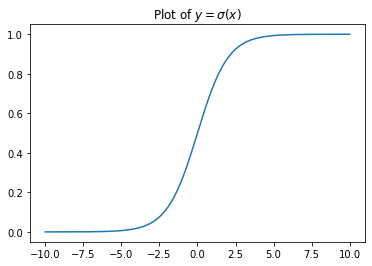

In [4]:
x_vals = np.linspace(-10,10,5000)
y_vals = sigma(x_vals)
plt.plot(x_vals,y_vals)
plt.title('Plot of $y = \sigma(x)$')
plt.show()

## 3. Maximum Likelihood Estimation.
- Suppose we observe the following pairs: $(\mathbf{x}^{(1)},y^{(1)}),(\mathbf{x}^{(2)},y^{(2)}),\ldots,(\mathbf{x}^{(N)},y^{(N)})$

- It is convenient to vectorize: $\mathbf{y} = [y^{(1)},y^{(2)},\ldots, y^{(N)}]^{\top}$ and $X = [\mathbf{x}^{(1)},\mathbf{x}^{(2)},\ldots,\mathbf{x}^{(N)}]$

- We further assume that all pairs $(\mathbf{x}^{(i)},y^{(i)})$ are **independent**

\begin{align}
\mathbb{P}\left[\mathbf{y} | X;\boldsymbol{\theta},b\right] = \mathbb{P}\left[ y^{(1)}|\mathbf{x}^{(1)};\boldsymbol{\theta},b \text{ and } y^{(2)}|\mathbf{x}^{(2)};\boldsymbol{\theta},b \text{ and }\ldots \text{ and } y^{(N)}|\mathbf{x}^{(N)};\boldsymbol{\theta},b\right] = \prod_{i=1}^{N} \mathbb{P}\left[y^{(i)}|\mathbf{x}^{(i)};\boldsymbol{\theta},b\right]
\end{align}

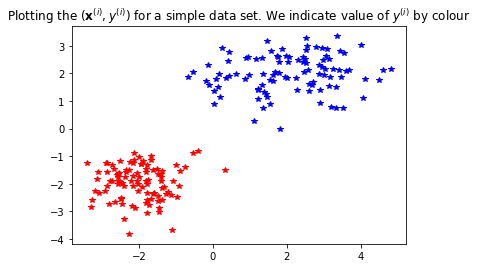

In [107]:
# Lets generate a toy example
mean_1 = [-2,-2]
cov_1 = [[0.5,0],[0,0.5]]
mean_2 = [2,2]
cov_2 = [[1.5,0],[0,0.5]]

# Generate the data using np.random library
X_1 = np.random.multivariate_normal(mean_1,cov_1,100)
X_2 = np.random.multivariate_normal(mean_2,cov_2,100)


X = np.concatenate([X_1,X_2],axis = 0) # concatenate data into single matrix
y = np.zeros([200,1])
y[100:200] = 1
N = 200 # number of data points

# Plot the data using pyplot
plt.plot(X_1[:,0],X_1[:,1],'r*')
plt.plot(X_2[:,0],X_2[:,1],'b*')
plt.title('Plotting the $(\mathbf{x}^{(i)},y^{(i)})$ for a simple data set. We indicate value of $y^{(i)}$ by colour')
plt.show()

- Recall that: $\mathbb{P}\left[y = 1|\mathbf{x};\boldsymbol{\theta},b \right] = h_{\mathbf{\theta},b}(\mathbf{x})$ and $\mathbb{P}\left[y = 0|\mathbf{x};\boldsymbol{\theta},b \right] = 1 - h_{\mathbf{\theta},b}(\mathbf{x})$


- It is convenient to write $\mathbb{P}[y|\mathbf{x};\theta,b] = h_{\boldsymbol{\theta},b}(\mathbf{x})^{y}\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}\right)^{1 - y}$

- Now: $\displaystyle \mathbb{P}\left[\mathbf{y} | X;\boldsymbol{\theta},b\right] = \prod_{i=1}^{N}h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})^{y^{(i)}}\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)^{1 - y^{(i)}}$


- **Maximum Likelihood Estimator:** $\displaystyle (\boldsymbol{\theta}^{*},b^{*}) := \text{argmax}_{\boldsymbol{\theta},b} \mathbb{P}\left[\mathbf{y} | X;\boldsymbol{\theta},b\right] = \text{argmax}_{\boldsymbol{\theta},b} \prod_{i=1}^{N}h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})^{y^{(i)}}\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)^{1 - y^{(i)}}$

- For several reasons, it is easier to maximize the **log-likelihood**
\begin{align*}
(\boldsymbol{\theta}^{*},b^{*}) & = \text{argmax}_{\boldsymbol{\theta},b} \log\left(\prod_{i=1}^{N}h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})^{y^{(i)}}\left(1 - h_{\boldsymbol{\theta},b}\mathbf{x}^{(i)}\right)^{1 - y^{(i)}}\right) \\
    & = \text{argmax}_{\boldsymbol{\theta},b} \sum_{i=1}^{N}\log\left(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})^{y^{(i)}}\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)^{1 - y^{(i)}}\right)\\
    & = \text{argmax}_{\boldsymbol{\theta},b} \sum_{i=1}^{N}\left(y^{(i)}\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})) + (1-y^{(i)}\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)\right)
\end{align*}

- For fixed data $X$ and $\mathbf{y}$:
    - Define $\ell_{i}(\boldsymbol{\theta},b) = y^{(i)}\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})) + (1-y^{(i)}\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)$
    - Define $\displaystyle L(\boldsymbol{\theta},b) = \sum_{i=1}^{N}\ell_{i}(\boldsymbol{\theta},b)$
    
- Problem becomes: $(\boldsymbol{\theta}^{*},b^{*}) = \text{argmax}_{\boldsymbol{\theta},b} L(\boldsymbol{\theta},b)$

## 3. Optimization part 1

- As noted before: $\displaystyle (\boldsymbol{\theta}^{*},b^{*}) = \text{argmax}_{\boldsymbol{\theta},b} L(\boldsymbol{\theta},b) \Leftrightarrow (\boldsymbol{\theta}^{*},b^{*}) = \text{argmin}_{\boldsymbol{\theta},b} -L(\boldsymbol{\theta},b)$

- **Claim:** $-L(\boldsymbol{\theta},b)$ is convex.
- Proof:
    - Sum of convex functions is convex.
    - Suffices to show $-\ell_{i}(\boldsymbol{\theta},b)$ is convex, **as functions of** $(\boldsymbol{\theta},b)$.
    - $-\ell_{i}(\boldsymbol{\theta},b) = -y^{(i)}\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})) - (1-y^{(i)})\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)$
    - Sum of convex functions is convex. Suffices to show that $-\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))$ and $-\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}\right)$ are convex.
    - Recall that:
    \begin{align}
    -\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})) = -\log\left(\sigma(\boldsymbol{\theta}^{\top}\mathbf{x} + b\right)
    \end{align}
     - Let $f(\boldsymbol{\theta},b) = \theta^{\top}\mathbf{x} + b$. Then $f$ is convex.
     - Let $g(z) = -\log(\sigma(z))$
     - *Remark: The proof I outlined in class was not quite correct. Specifically, the function $g(z)$ is not non-decreasing. The theorem is true however, and below I will show how to modify the proof to get something that is correct*
    - Note that $f(\boldsymbol{\theta},b)$ is an **affine** function. That is, it is a linear function ($\theta^{\top}\mathbf{x}$) plus a shift ($+b$).
    - It is a fact that if $f$ is affine and $g(z)$ is convex then $g\left(f(\boldsymbol{\theta},b)\right)$ is convex.
    - So, we need only show that $g(z)$ is convex. We'll do this by showing its second derivative is positive:
    \begin{align}
        & g^{'}(z) = -\frac{1}{\sigma(z)}\left(\sigma(z)(1-\sigma(z)\right) = \sigma(z) - 1 \\
        & g^{''}(z) = \sigma^{'}(z) = \sigma(z)(1 - \sigma(z)) > 0 \text{ as } 0 < \sigma(z) < 1 \text{ for all } z
    \end{align}
    
    
    
- **Key Point:** ``Training'' logistic regression model = solving convex optimization problem.

## 4. Optimization part 2

- We shall solve $\boldsymbol{\theta}^{*} = \text{argmin}_{\boldsymbol{\theta}} -L(\boldsymbol{\theta})$ using **gradient descent**

\begin{align}
& \nabla_{\boldsymbol{\theta},b}L(\boldsymbol{\theta},b) = \nabla_{\boldsymbol{\theta},b}\sum_{i=1}^{N}\ell_{i}(\boldsymbol{\theta},b) = \sum_{i=1}^{N}\nabla_{\boldsymbol{\theta},b}\ell_{i}(\boldsymbol{\theta},b) \\
\end{align}
\begin{align}
\frac{\partial}{\partial\theta_k}\ell_{i}(\boldsymbol{\theta},b) &= \frac{\partial}{\partial\theta_k}\left(y^{(i)}\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})) + (1-y^{(i)}\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)\right)\\
        & = y^{(i)}\frac{\partial}{\partial\theta_k}\left(\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\right) + (1-y^{(i)})\frac{\partial}{\partial\theta_k}\left(\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)\right)\\
\end{align}

- Let $f(\boldsymbol{\theta},b) = \theta^{\top}\mathbf{x} + b$ and $g(z) = \log(\sigma(z))$. Then by chain rule:

\begin{align}
\frac{\partial}{\partial\theta_k}\left(\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\right) & = \frac{\partial}{\partial\theta_k}\left(g(f(\boldsymbol{\theta},b))\right) = g^{'}(f(\boldsymbol{\theta},b))\frac{\partial}{\partial\theta_k}f(\boldsymbol{\theta},b)
\end{align}

- Easy part:
\begin{align}
    \frac{\partial}{\partial\theta_k}f(\boldsymbol{\theta},b) = \frac{\partial}{\partial\theta_k}\left(\theta^{\top}\mathbf{x}^{(i)} + b\right)  = x^{(i)}_{k}
\end{align}

- Slightly harder part:
\begin{align}
g^{'}(z) & = \frac{d}{dz}\left(\log\sigma(z)\right) = \frac{1}{\sigma(z)}\frac{d}{dz}\left(\sigma(z)\right) \\
        & = \frac{1}{\sigma(z)}\left(\sigma(z)(1- \sigma(z))\right) = 1 - \sigma(z)
\end{align}

- So:
\begin{align}
\frac{\partial}{\partial\theta_k}\left(\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\right) & = \left(1 - \sigma\left(f(\boldsymbol{\theta},b)\right)\right)x^{(i)}_{k} = \left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)x^{(i)}_{k}
\end{align}

- Similarly:
\begin{align}
\frac{\partial}{\partial\theta_k}\left(\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)\right) = -h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})x^{(i)}_{k}
\end{align}

- And so:
\begin{align}
\frac{\partial}{\partial\theta_k} \ell_{i}(\boldsymbol{\theta},b) &= y^{(i)}\frac{\partial}{\partial\theta_k}\left(\log(h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\right) + (1-y^{(i)})\frac{\partial}{\partial\theta_k}\left(\log\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)\right)\\
    &= y^{(i)}\left(1 - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})\right)x^{(i)}_{k} - (1-y^{(i)})h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)})x^{(i)}_{k}\\
    & = (y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))x^{(i)}_{k}
\end{align}

- So the gradient is:
\begin{align}
& \nabla_{\boldsymbol{\theta}}\ell_{i}(\boldsymbol{\theta},b) = (y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\mathbf{x}^{(i)} \\
& \frac{\partial}{\partial b}\ell_{i}(\boldsymbol{\theta},b) = (y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))
\end{align}

## 5. Optimization Part 2

- **Recall:** Want to solve $\boldsymbol{\theta}^{*},b^{*} = \text{argmin}_{\boldsymbol{\theta},b}-L(\boldsymbol{\theta},b)$. 



- $\nabla_{\boldsymbol{\theta}} (-L(\boldsymbol{\theta},b) = \sum_{i=1}^{N}\nabla_{\boldsymbol{\theta}}\left(-\ell_{i}(\boldsymbol{\theta},b)\right) = -\sum_{i=1}^{N}(y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\mathbf{x}^{(i)}$



- $\frac{\partial}{\partial b}(-L(\boldsymbol{\theta},b) = -\sum_{i=1}^{N} \frac{\partial}{\partial b}\ell_{i}(\boldsymbol{\theta},b) = -\sum_{i=1}^{N}(y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))$

- **Gradient Descent:**
\begin{align}
& \boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_{k} - \alpha\nabla_{\boldsymbol{\theta}}\left(-L(\boldsymbol{\theta}_k,b_k)\right) = \boldsymbol{\theta}_{k} + \alpha \sum_{i=1}^{N}(y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))\mathbf{x}^{(i)} \\
& b_{k+1} = b_{k} - \alpha\frac{\partial}{\partial b}\left(-L(\boldsymbol{\theta}_k,b_k)\right) = b_{k} + \alpha \sum_{i=1}^{N}(y^{(i)} - h_{\boldsymbol{\theta},b}(\mathbf{x}^{(i)}))
\end{align}

In [108]:
def h(theta,b,x):
    return sigma(np.dot(theta,x) + b)

In [109]:
def TrainingLogisticRegression(theta_0,b_0,X,y,alpha,K_max):
    # Function for training logistic regression model
    # Inputs:
        # theta_0,b_0 : (random) initializations for parameters
        # X,y : labeled training data
        # alpha: step size/ learning rate
        # K_max: max number of iterations.
    theta = np.squeeze(theta_0)
    b = b_0
    N = X.shape[0]
    d = X.shape[1]
    loss_function_trajectory = np.zeros([K_max,1])
    for k in range(K_max):
        theta_grad = 0
        b_grad = 0
        loss_function_value = 0
        for i in range(N):
            theta_grad += (y[i] - h(theta,b,X[i,:]))*X[i,:]
            b_grad += y[i] - h(theta,b,X[i,:])
            loss_function_value += -y[i]*np.log(h(theta,b,X[i,:])) -(1-y[i])*np.log(1 - h(theta,b,X[i,:])) 
        theta += alpha*theta_grad
        b += alpha*b_grad
        loss_function_trajectory[k] = loss_function_value
        if k% 50 == 0:
            print(loss_function_value)
    return theta,b,loss_function_trajectory

In [110]:
## Testing this on our toy model

# Splitting data into test and train
All_indices = range(0,200)
Train_indices = np.random.choice(All_indices,size=160,replace=False)
Test_indices = np.setdiff1d(All_indices,Train_indices)

X_train = X[Train_indices,:]
y_train = y[Train_indices]

X_test = X[Test_indices,:]
y_test = y[Test_indices,:]

# Initializing parameters
theta_0 = np.random.randn(2,1)
b_0 = np.random.randn(1)
alpha = 0.01
K_max = 500

# training
theta,b,loss_function_trajectory = TrainingLogisticRegression(theta_0,b_0,X_train,y_train,alpha,K_max)

[314.44551707]
[0.64927972]
[0.4199044]
[0.31763663]
[0.25862898]
[0.21975987]
[0.19200079]
[0.17106581]
[0.15464553]
[0.14137937]


In [111]:
print(theta)
print(b)

[3.07638608 3.45499504]
[0.23950469]


In [112]:
def Classifier(theta,b,x):
    score = h(theta,b,x)
    classification = np.round(score)
    return score,classification

In [115]:
i = 23
score, classification = Classifier(theta,b,X_test[i,:])
#print(classification)
#print(y[1])
print('Predicted Label is ' + str(int(classification)) + ' while the true label is ' + str(int(y_test[i])))

Predicted Label is 1 while the true label is 1


In [116]:
# Compute test accuracy
CorrectlyClassified = 0
for i in range(40):
    _, classification = Classifier(theta,b,X_test[i,:])
    if int(classification) == int(y_test[i]):
        CorrectlyClassified += 1.0
Accuracy = 100*CorrectlyClassified/40
print(Accuracy)

100.0


## 6. Classification Boundary
- Observe that if $\boldsymbol{\theta}^{\top}\mathbf{x} + b = 0$ then $h_{\boldsymbol{\theta},b}(\mathbf{x}) = \frac{1}{2}$. 
- This is the boundary between the two classses

\begin{align}
& \theta_1x_1 + \theta_2x_2 + b = 0 \\
\Rightarrow & \theta_2x_2 = -\theta_1x_1 - b \\
\Rightarrow & x_2 = \frac{-\theta_1}{\theta_2}x_1 - \frac{b}{\theta_1}
\end{align}

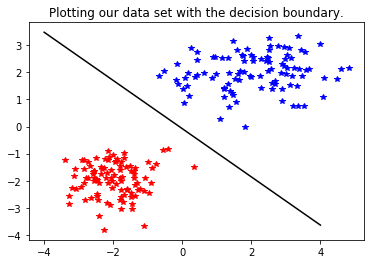

In [117]:
## Let's visualize the classification boundary
x_vals = np.linspace(-4,4,5000)
y_vals = -(theta[0]/theta[1])*x_vals - b/theta[0]
plt.plot(x_vals,y_vals,'k')
plt.plot(X_1[:,0],X_1[:,1],'r*')
plt.plot(X_2[:,0],X_2[:,1],'b*')
plt.title('Plotting our data set with the decision boundary.')
plt.show()

## 7. Classification Boundary Part 2
- Let $\mathbf{x} = [x_1,x_2]$ be a data point.
- The quantity $\boldsymbol{\theta}^{\top}\mathbf{x} + b$ represents the **signed distance** from $\mathbf{x}$ to the decision boundary.
- The sigmoid function, $\sigma(z)$, converts this distance to $\approx 0$ if negative, and $\approx 1$ if positive.

<function matplotlib.pyplot.show(*args, **kw)>

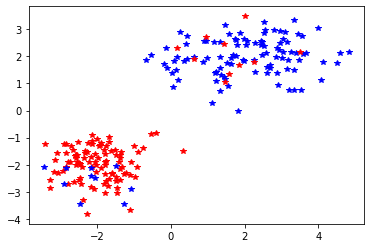

In [118]:
## Robustness: lets ''poison'' our data set:
n_poison = 10
X_poison_1 = np.random.multivariate_normal(mean_2,cov_2,n_poison)
X_poison_2 = np.random.multivariate_normal(mean_1,cov_1,n_poison)
y_poison_1 = np.zeros((10,1))
y_poison_2 = np.ones((10,1))

X_new = np.concatenate([X,X_poison_1,X_poison_2])
y_new = np.concatenate([y,y_poison_1,y_poison_2])

# Plot the poisoned data using pyplot
plt.plot(X_1[:,0],X_1[:,1],'r*')
plt.plot(X_2[:,0],X_2[:,1],'b*')
plt.plot(X_poison_1[:,0],X_poison_1[:,1],'r*')
plt.plot(X_poison_2[:,0],X_poison_2[:,1],'b*')
plt.show

In [119]:
# Train using poisoned data set:
# Splitting data into test and train
All_indices = range(0,220)
Train_indices = np.random.choice(All_indices,size=180,replace=False)
Test_indices = np.setdiff1d(All_indices,Train_indices)

X_train = X_new[Train_indices,:]
y_train = y_new[Train_indices]

X_test = X_new[Test_indices,:]
y_test = y_new[Test_indices,:]

# Initializing parameters
theta_0 = np.random.randn(2,1)
b_0 = np.random.randn(1)
alpha = 0.01
K_max = 200

# training
theta_new,b_new,loss_function_trajectory = TrainingLogisticRegression(theta_0,b_0,X_train,y_train,alpha,K_max)

[78.28833246]
[64.67725996]
[64.67719246]
[64.67719246]


In [120]:
# Compute test accuracy
CorrectlyClassified = 0
for i in range(40):
    _, classification = Classifier(theta,b,X_test[i,:])
    if int(classification) == int(y_test[i]):
        CorrectlyClassified += 1.0
Accuracy = 100*CorrectlyClassified/40
print(Accuracy)

95.0


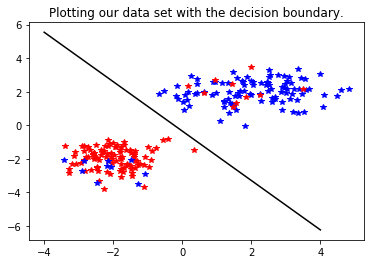

In [121]:
## Let's visualize the classification boundary for training with poisoned data.
x_vals = np.linspace(-4,4,5000)
y_vals = -(theta_new[0]/theta_new[1])*x_vals - b_new/theta_new[0]
plt.plot(x_vals,y_vals,'k')
plt.plot(X_1[:,0],X_1[:,1],'r*')
plt.plot(X_2[:,0],X_2[:,1],'b*')
plt.plot(X_poison_1[:,0],X_poison_1[:,1],'r*')
plt.plot(X_poison_2[:,0],X_poison_2[:,1],'b*')
plt.title('Plotting our data set with the decision boundary.')
plt.show()

## 8. Summary
- **Pros** of logistic regression:
    - Easy to implement and train.
    - Memory-efficient.
    - Interpretable.
    - Loss function is convex, so training is guaranteed to converge.
    - Robust to errors/noise.
    
- **Cons:** of logistic regression:
    - Can only classify linearly separable data.
    - Sometimes data very close to decision boundary, so not robust to adversarial attack.
    
- **Further topics**
    - Kernel Logistic Regression: can have non-linear decision boundary.
    - Logistic Regression for multiple classes.
    - Other training algorithms; e.g. Newton's method or SGD.
    - Support Vector Machine: similar, but is more robust to adversarial attack.